In [2]:
import numpy as np
import pandas as pd
from scipy.stats import ecdf
from lifelines import KaplanMeierFitter
from lifelines import CoxPHFitter
from lifelines.statistics import proportional_hazard_test
from lifelines import CoxPHFitter, WeibullAFTFitter
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

import testis_model as tm
import os
from analysis import small_label_settings

In [3]:
filepath = os.path.join('..', 'model_simulations', 'all_clone_results.csv')
df = pd.read_csv(filepath)

df = df[df['n_transient'] > 1].copy()

exp_scenario = 'full_pipeline'
df['died_early'] = df['last_time'] != df['max_time']
df.head()

,scenario,fish,duplicate,clone,init_time,init_freq,last_time,min_time,max_time,max_freq,n_transient,size,avg_freq_change,r_opt,l_max,lower,upper,l_null,died_early
0,n500_r15_y6,0,0,0,6.0,0.423404,12.0,6.0,17.0,0.000000,5,0.179610,0.058983,66.333357,-66.968960,24.140822,215.679403,-1572.903572,True
1,n500_r15_y6,0,0,1,6.0,0.331206,17.0,6.0,17.0,0.831206,8,0.670479,-0.045455,28.356251,-112.704281,11.747374,84.913303,-761.535855,False
2,n500_r15_y6,0,0,2,6.0,0.175887,17.0,6.0,17.0,0.168794,8,0.141223,0.000645,24.619601,-106.026792,11.252589,59.327711,-472.252913,False
5,n500_r15_y6,0,1,0,6.0,0.528369,17.0,6.0,17.0,0.898582,8,0.783333,-0.033656,30.466277,-105.465431,13.190731,83.056649,-568.929085,False
6,n500_r15_y6,0,1,1,6.0,0.197163,17.0,6.0,17.0,0.101418,8,0.177128,0.008704,20.115937,-103.618320,8.390094,58.532763,-311.664705,False


Text(0, 0.5, 'Count')

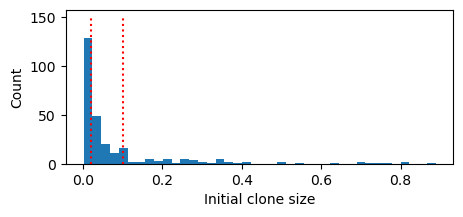

In [4]:
small_cutoff = 0.02
large_cutoff = 0.10

fig, ax = plt.subplots(figsize = (5, 2))

real_df = df.query('scenario == @exp_scenario')
ax.hist(real_df['init_freq'], bins=40)
ax.vlines(x=small_cutoff, ymin=0, ymax=150, colors='r', linestyles='dotted', zorder=1)
ax.vlines(x=large_cutoff, ymin=0, ymax=150, colors='r', linestyles='dotted', zorder=1)
ax.set_xlabel('Initial clone size')
ax.set_ylabel('Count')

In [5]:
print(f"""\
{100*(real_df['init_freq'] < small_cutoff).mean():.1f}% of experimental clones have a size below {small_cutoff:.2f}, \
{100*((real_df['init_freq'] > small_cutoff) & (real_df['init_freq'] < large_cutoff)).mean():.1f}% \
have a size between {small_cutoff:.2f} and {large_cutoff:.2f}, and \
{100*(real_df['init_freq'] > large_cutoff).mean():.1f}% of clones have a size above {large_cutoff:.2f}.\
""")

44.0% of experimental clones have a size below 0.02, 33.6% have a size between 0.02 and 0.10, and 22.4% of clones have a size above 0.10.


In [6]:
df.loc[df['init_freq'] < large_cutoff, 'tertile'] = 'medium'
df.loc[df['init_freq'] < small_cutoff, 'tertile'] = 'small'
df.loc[df['init_freq'] >= large_cutoff, 'tertile'] = 'large'

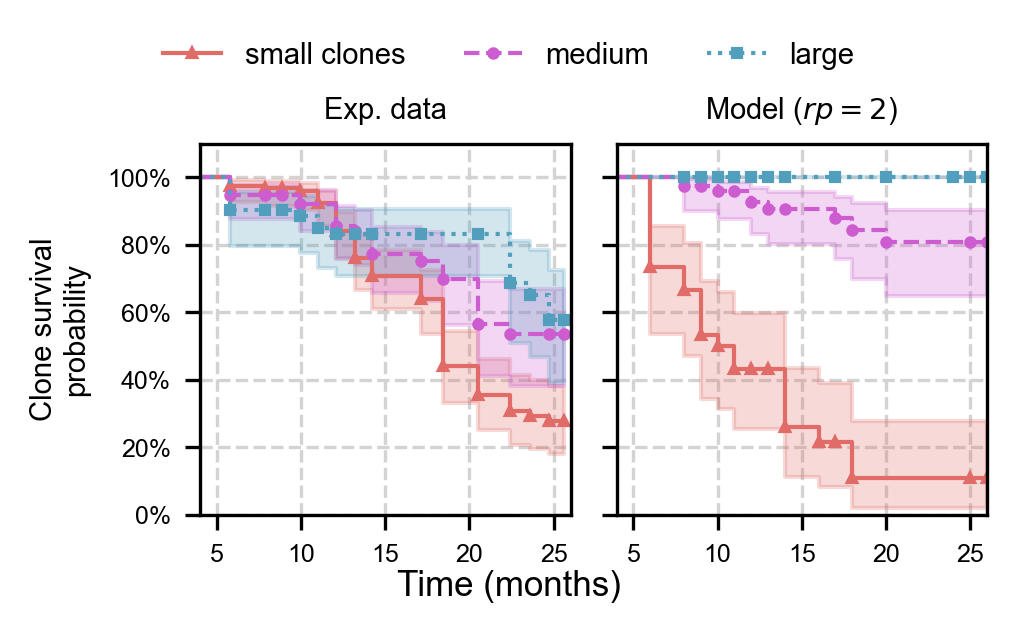

In [7]:
plt.style.use('default')
plt.rcParams.update(small_label_settings)

supplemental_mode = False

if supplemental_mode:
    scenarios = ['full_pipeline', 'full_pipeline_TQ14', 'full_pipeline_MP0.95', 'no_cluster', 'r36_rp2_mimic']
    scenarios_labels = ['Exp. data', 'Exp. data (TQ 14)', 'Exp. data (MP 0.95)', 'Exp. data (no cluster)', 'Model ($rp=2$)']
    fig, ax = plt.subplots(1, 5, figsize=(6.7, 1.5), dpi=300, sharey=True)
    filepath = os.path.join('images', 'survivorship_supplement.svg')
else:
    scenarios = ['full_pipeline', 'r36_rp2_mimic']
    scenarios_labels = ['Exp. data', 'Model ($rp=2$)']
    fig, ax = plt.subplots(1, 2, figsize=(3.4, 2), dpi=300, sharey=True)
    filepath = os.path.join('images', 'survivorship.svg')

compare_scenario = 'r36_rp2_mimic'

# Tertile definitions and plotting styles
tertiles = {
    "small":  dict(color="#e06b67", marker="^", linestyle="-",  label="small" if supplemental_mode else 'small clones'),
    "medium": dict(color="#cd5cd1", marker="o", linestyle="--", label="medium"),
    "large":  dict(color="#519ebd", marker="s", linestyle=":",  label="large"),
}

def subset_data(df, scenario, tertile):
    """Return the appropriate subset for a given scenario and tertile."""
    base = df.query("scenario == @scenario and tertile == @tertile")
    if scenario == exp_scenario:
        return base
    return base.query("duplicate == 0")

def plot_km(ax, data, style):
    """Fit and plot a Kaplan–Meier curve with consistent styling."""
    km = KaplanMeierFitter()
    km.fit(durations=data["last_time"], event_observed=data["died_early"])
    km.plot_survival_function(
        ax=ax,
        color=style["color"],
        linestyle=style["linestyle"],
        marker=style["marker"],
        markersize=2,
        linewidth=1,
        label=style["label"],
    )

for i, (scenario, label) in enumerate(zip(scenarios, scenarios_labels)):
    for tertile, style in tertiles.items():
        data = subset_data(df, scenario, tertile)
        plot_km(ax[i], data, style)

    ax[i].set_xlabel("")
    ax[i].grid(True, linestyle="--", linewidth=0.8, color="lightgray")
    ax[i].set_axisbelow(True)
    ax[i].set_xticks([5, 10, 15, 20, 25])
    ax[i].set_xlim([4, 26])
    ax[i].set_ylim([0, 1.1])
    ax[i].set_title(label)
    ax[i].legend_.remove()

ax[0].set_ylabel("Clone survival\nprobability")
ax[0].yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))

handles, labels = ax[0].get_legend_handles_labels()
if supplemental_mode:
    # fig.legend(handles, labels, loc="center left", bbox_to_anchor=(1.0, 0.6), ncol=1, frameon=False, title = 'Clone size')
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.06), ncol=3, frameon=False)
else:
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.08), ncol=3, frameon=False)
fig.supxlabel("Time (months)", y=0.1)

plt.tight_layout()
plt.savefig(filepath, bbox_inches = 'tight', pad_inches = 0)

## Cox PH Model

In [9]:
exp_scenario = 'full_pipeline'
sim_scenario = 'r36_rp2_mimic'

df2 = df.query(
    "scenario == @exp_scenario or (scenario == @sim_scenario and duplicate == 0)"
).copy()
df2['scenario'] = pd.Categorical(df2['scenario'])
df2['scenario'] = df2['scenario'].cat.reorder_categories(
    [exp_scenario, sim_scenario]
)

In [10]:
cph = CoxPHFitter()
cph.fit(df2, duration_col='last_time', event_col='died_early', formula='init_freq * scenario')
cph.print_summary()

<lifelines.CoxPHFitter: fitted with 448 total observations, 310 right-censored observations>
             duration col = 'last_time'
                event col = 'died_early'
      baseline estimation = breslow
   number of observations = 448
number of events observed = 138
   partial log-likelihood = -697.29
         time fit was run = 2026-04-30 02:55:04 UTC

---
                                      coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                             
init_freq                            -1.82      0.16      0.86           -3.51           -0.13                0.03                0.88
scenario[T.r36_rp2_mimic]             2.13      8.43      0.31            1.52            2.74                4.58               15.52
init_freq:scenario[T.r36_rp2_mimic] -84.38      0.00     14.29         -112.39          -56.37                0.00                0.00

                                     cmp to     z      p  -log2(p)
covariate                                                         
init_freq                              0.00 -2.11   0.03      4.84
scenario[T.r36_rp2_mimic]              0.00  6.85 <0.005     36.99
init_freq:scenario[T.r36_rp2_mimic]    0.00 -5.90 <0.005     28.07
---
Concordance = 0.74
Partial AIC = 1400.58
log-likelihood ratio test = 119.61 on 3 df
-log2(p) of ll-ratio test = 83.15

In [12]:
results = proportional_hazard_test(cph, df2, time_transform='rank')
print(results.summary)

                                     test_statistic         p  -log2(p)
init_freq                                  4.864758  0.027411  5.189120
init_freq:scenario[T.r36_rp2_mimic]        0.560426  0.454088  1.138955
scenario[T.r36_rp2_mimic]                  5.203343  0.022543  5.471145


## Weibull Model

In [13]:
def fit_weibull(df, exp_scenario, sim_scenario, duplicate):
    df2 = df.query(
        "scenario == @exp_scenario or (scenario == @sim_scenario and duplicate == @duplicate)"
    ).copy()
    df2['scenario'] = pd.Categorical(df2['scenario'])
    df2['scenario'] = df2['scenario'].cat.reorder_categories(
        [exp_scenario, sim_scenario]
    )

    aft = WeibullAFTFitter()
    aft.fit(df2, duration_col="last_time", event_col="died_early", formula="init_freq * scenario")
    return aft, df2

In [14]:
exp_scenario = 'full_pipeline'
sim_scenario = 'r36_rp2_mimic'

aft, df2 = fit_weibull(df, exp_scenario, sim_scenario, 0)
aft.print_summary()

<lifelines.WeibullAFTFitter: fitted with 448 total observations, 310 right-censored observations>
             duration col = 'last_time'
                event col = 'died_early'
   number of observations = 448
number of events observed = 138
           log-likelihood = -577.82
         time fit was run = 2026-04-30 02:55:21 UTC

---
                                             coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
param   covariate                                                                                                                            
lambda_ Intercept                            3.21     24.74      0.05            3.11            3.31               22.45               27.27
        init_freq                            0.80      2.23      0.36            0.09            1.51                1.09                4.53
        scenario[T.r36_rp2_mimic]           -0.88      0.41      0.14           -1.15           -0.62                0.32                0.54
        init_freq:scenario[T.r36_rp2_mimic] 36.10  4.78e+15      6.27           23.82           48.38            2.22e+10            1.03e+21
rho_    Intercept                            0.88      2.40      0.07            0.74            1.01                2.11                2.75

                                             cmp to     z      p  -log2(p)
param   covariate                                                         
lambda_ Intercept                              0.00 64.77 <0.005       inf
        init_freq                              0.00  2.21   0.03      5.19
        scenario[T.r36_rp2_mimic]              0.00 -6.52 <0.005     33.73
        init_freq:scenario[T.r36_rp2_mimic]    0.00  5.76 <0.005     26.84
rho_    Intercept                              0.00 12.95 <0.005    124.97
---
Concordance = 0.73
AIC = 1165.64
log-likelihood ratio test = 127.06 on 3 df
-log2(p) of ll-ratio test = 88.47

In [15]:
p_initfreq = aft.summary['p'].loc['lambda_', 'init_freq']
p_interact = aft.summary['p'].loc['lambda_', f'init_freq:scenario[T.{sim_scenario}]']

print(f'The p value of initial frequency dependence in the experimental data is {p_initfreq:.2e}. \
The p value of interaction is {p_interact:.2e}.')

The p value of initial frequency dependence in the experimental data is 2.74e-02. The p value of interaction is 8.31e-09.


## Repeat statistical test over multiple simulation runs

The purpose of this section is to make sure our first test was not "lucky."
You can set `exp_scenario` to `full_pipeline`, `full_pipeline_trunc`, or `no_collapse`.

In [16]:
rs = [0.5, 1, 1.5, 2, 2.5, 3, 4, 5, 6]
rows = []

exp_scenario = 'full_pipeline'

for r in rs:
    compare_scenario = f'r36_rp{r}_mimic'

    for d in range(10):
        aft, df2 = fit_weibull(df, exp_scenario, compare_scenario, d)
        summary = aft.summary
    
        intercept = summary.loc[('lambda_', 'Intercept')]
        init_freq = summary.loc[('lambda_', 'init_freq')]
        interact = summary.loc[('lambda_', f'scenario[T.{compare_scenario}]')]
        interact_init_freq = summary.loc[('lambda_', f'init_freq:scenario[T.{compare_scenario}]')]
        
        row = {'r': r, 'duplicate': d, 'intercept': intercept.p, 'init. freq.': init_freq.p,
              'interact': interact.p, 'interact init_freq': interact_init_freq.p}
    
        overall_survive = df2.query('scenario == @compare_scenario')['died_early'].mean() * 100
        row['overall_survive'] = f'{overall_survive:.0f}%'
        rows.append(row)

# Build DataFrame
results_df = pd.DataFrame(rows)
results_df.set_index("r", inplace=True)

In [17]:
not_sig = results_df[results_df['interact init_freq'] > 0.05]
print(f'There was {len(not_sig)} non-significant init_freq interaction out of {len(results_df)} total tests. \
The not significant result(s) are below:')

not_sig

There was 0 non-significant init_freq interaction out of 90 total tests. The not significant result(s) are below:


,duplicate,intercept,init. freq.,interact,interact init_freq,overall_survive
r,,,,,,
